# Commercial Vehicle Reliability & Failure Pattern Analysis

----------

## Project Overview

This project analyses MOT test data to identify vehicle reliability patterns and common failure factors in commercial vehicles. The analysis focuses on vehicle age, mileage, vehicle characteristics, test results, and recorded defects to understand how failure rates vary across different vehicle conditions.

## Problem Statement

Vehicle failures are often analysed based on individual factors such as vehicle age, mileage, or failure type. However, failure risk can be influenced by the combination of vehicle age, total kilometres travelled, vehicle type, previous test history, and previous defects. This project aims to analyse these factors together to identify hidden vehicle failure patterns and understand how failure risk changes across different vehicle conditions.

## Project Objective

- Analyse vehicle failure patterns using MOT test data.
- Identify how failure rates vary with vehicle age and mileage.
- Analyse failure patterns across vehicle characteristics such as make, fuel type, vehicle class, and engine capacity.
- Identify common vehicle defects and defect categories.
- Understand the combined effect of vehicle age and mileage on failure rates.
- Generate insights that can support preventive maintenance planning.

## Dataset Description

The project uses the UK DVSA Anonymised MOT Tests and Results dataset. The dataset contains MOT test records with information such as vehicle details, test results, mileage, vehicle class, fuel type, engine capacity, and test dates. A separate MOT failure item dataset is used to analyse specific vehicle defects and failure patterns.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Exploratory Data Analysis

The dataset is analysed to understand vehicle test results, vehicle characteristics, mileage, age, and failure patterns. The analysis begins with basic data understanding and cleaning, followed by individual factor analysis and combined factor analysis.

In [5]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for data visualization
import matplotlib.pyplot as plt

In [6]:
file_path = r"D:\EDA PROJECT\Commercial Vehicle Reliability & Failure Pattern Analysis\datasets\raw_dataset.csv\test_result_202401.csv"

In [7]:
# Load the MOT test results dataset
# escapechar="\\" allows escaped characters within CSV fields to be read correctly
df = pd.read_csv(
    file_path,
    escapechar="\\"
)

# Display the number of rows and columns in the dataset
print(df.shape)

C:\Users\User\AppData\Local\Temp\ipykernel_12380\854412898.py:3: DtypeWarning: Columns (0: test_id, 1: vehicle_id, 2: test_class_id, 3: test_mileage, 4: cylinder_capacity) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


(6140803, 15)


In [8]:
# Display the first five rows of the dataset
df.head()

,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date,completed_date
0,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
1,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
2,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
3,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
4,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z


In [9]:
# Display the dataset structure, column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6140803 entries, 0 to 6140802
Data columns (total 15 columns):
 #   Column             Dtype 
---  ------             ----- 
 0   test_id            object
 1   vehicle_id         object
 2   test_date          str   
 3   test_class_id      object
 4   test_type          str   
 5   test_result        str   
 6   test_mileage       object
 7   postcode_area      str   
 8   make               str   
 9   model              str   
 10  colour             str   
 11  fuel_type          str   
 12  cylinder_capacity  object
 13  first_use_date     str   
 14  completed_date     str   
dtypes: object(5), str(10)
memory usage: 702.8+ MB


In [10]:
# Count the number of missing values in each column
df.isnull().sum()

test_id                  0
vehicle_id               0
test_date                0
test_class_id            0
test_type                0
test_result              0
test_mileage         48600
postcode_area            0
make                     0
model                    9
colour                   0
fuel_type                0
cylinder_capacity    47727
first_use_date           0
completed_date           0
dtype: int64

In [11]:
# Calculate the percentage of missing values in each column
# Multiply by 100 to express the missing-value ratio as a percentage
df.isnull().mean() * 100

test_id              0.000000
vehicle_id           0.000000
test_date            0.000000
test_class_id        0.000000
test_type            0.000000
test_result          0.000000
test_mileage         0.791427
postcode_area        0.000000
make                 0.000000
model                0.000147
colour               0.000000
fuel_type            0.000000
cylinder_capacity    0.777211
first_use_date       0.000000
completed_date       0.000000
dtype: float64

In [12]:
# Filter records where test mileage is missing
# Display selected vehicle details for the first 10 records
df[df["test_mileage"].isnull()][
    ["vehicle_id", "make", "model", "test_mileage", "cylinder_capacity"]
].head(10)

,vehicle_id,make,model,test_mileage,cylinder_capacity
175,1296279998,FORD,FOCUS,NaN,1596.0
268,1256446192,KIA,PICANTO,NaN,999.0
561,900323874,FORD,FOCUS,NaN,1596.0
562,900323874,FORD,FOCUS,NaN,1596.0
593,252842375,FORD,TRANSIT,NaN,2198.0
636,1014186639,FORD,TRANSIT,NaN,2198.0
757,933236941,TESLA,MODEL S,NaN,NaN
758,933236941,TESLA,MODEL S,NaN,NaN
2058,722508122,VOLKSWAGEN,GOLF,NaN,1896.0
2252,1170337218,VOLKSWAGEN,CAMPER,NaN,1390.0


In [13]:
# Count the number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(2292284)

In [14]:
# Display the first 10 rows that are part of duplicate records
# keep=False marks all occurrences of duplicated rows for inspection
df[df.duplicated(keep=False)].head(10)

,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date,completed_date
0,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
1,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
2,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
3,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
4,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
5,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
6,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
7,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
8,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z
9,886090729,1182957512,2024-01-02,4,NT,P,71614.0,OX,PORSCHE,911,RED,PE,3824.0,2010-09-01,2024-01-02T10:19:28.000Z


In [15]:
# Remove duplicate rows from the dataset
df = df.drop_duplicates()

# Display the updated number of rows and columns
print(df.shape)

(3848519, 15)


In [16]:
# Convert test mileage values into numeric format for analysis
# Invalid or non-numeric values are converted to NaN
df["test_mileage"] = pd.to_numeric(
    df["test_mileage"],
    errors="coerce"
)

In [17]:
# Check the data type of the test mileage column
df["test_mileage"].dtype

dtype('float64')

In [18]:
# Convert engine capacity values into numeric format for analysis
# Invalid or non-numeric values are converted to NaN
df["cylinder_capacity"] = pd.to_numeric(
    df["cylinder_capacity"],
    errors="coerce"
)

In [19]:
# Check the data type of the engine capacity column
df["cylinder_capacity"].dtype

dtype('float64')

### Date and Time Data Preparation

The date and time columns are converted into a proper datetime format to support time-based analysis and accurate calculation of vehicle age.

In [20]:
# Remove the header-like row that contains "test_date" in the date column
df = df[df["test_date"] != "test_date"]

In [21]:
# Convert the test date column into datetime format
# This enables accurate date-based analysis and calculations
df["test_date"] = pd.to_datetime(df["test_date"])

In [22]:
# Verify whether any header-like rows remain in the test_date column
# An empty result means the unwanted header-like row has already been removed
df[df["test_date"] == "test_date"].head()

,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date,completed_date


In [23]:
# Convert the first use date column into datetime format
# This enables accurate vehicle age calculations and date-based analysis
df["first_use_date"] = pd.to_datetime(df["first_use_date"])

In [24]:
# Convert the completed date column into datetime format
# This enables accurate date-based analysis and time-related calculations
df["completed_date"] = pd.to_datetime(df["completed_date"])

In [25]:
# Display the dataset structure, column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
Index: 3848518 entries, 0 to 6140802
Data columns (total 15 columns):
 #   Column             Dtype              
---  ------             -----              
 0   test_id            object             
 1   vehicle_id         object             
 2   test_date          datetime64[us]     
 3   test_class_id      object             
 4   test_type          str                
 5   test_result        str                
 6   test_mileage       float64            
 7   postcode_area      str                
 8   make               str                
 9   model              str                
 10  colour             str                
 11  fuel_type          str                
 12  cylinder_capacity  float64            
 13  first_use_date     datetime64[us]     
 14  completed_date     datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), datetime64[us](2), float64(2), object(3), str(7)
memory usage: 469.8+ MB


In [26]:
# Reset the DataFrame index after removing rows
# drop=True creates a new continuous index without keeping the old index
df = df.reset_index(drop=True)

In [27]:
# Count the number of tests recorded for each test result category
df["test_result"].value_counts()

test_result
P        2869955
F         769928
PRS       184917
ABR        21152
ABA         2565
ABRVE          1
Name: count, dtype: int64

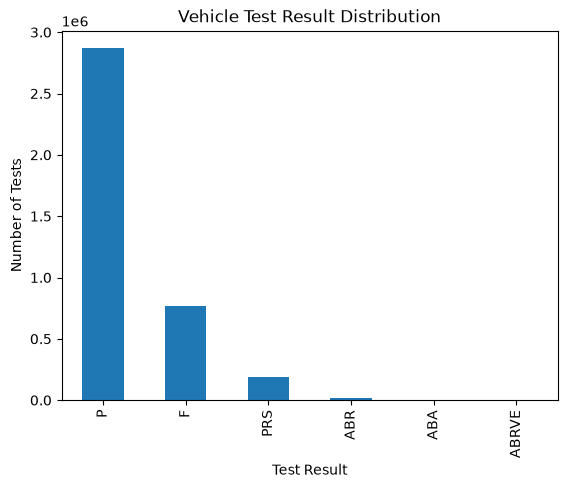

In [28]:
# Plot the distribution of vehicle test results
df["test_result"].value_counts().plot(kind="bar")

# Add a title and axis labels to the chart
plt.title("Vehicle Test Result Distribution")
plt.xlabel("Test Result")
plt.ylabel("Number of Tests")

# Display the chart
plt.show()

In [29]:
# Calculate summary statistics for the mileage of failed vehicle tests
# This helps understand the mileage distribution among failed tests
df[df["test_result"] == "F"]["test_mileage"].describe()

count    766429.000000
mean      94447.888846
std       47922.825469
min           1.000000
25%       60494.000000
50%       88477.000000
75%      120746.000000
max      999999.000000
Name: test_mileage, dtype: float64

In [30]:
# Calculate summary statistics for the mileage of passed vehicle tests
# This helps understand the mileage distribution among passed tests
df[df["test_result"] == "P"]["test_mileage"].describe()

count    2.863536e+06
mean     7.624481e+04
std      4.770309e+04
min      1.000000e+00
25%      4.083100e+04
50%      6.787750e+04
75%      1.021710e+05
max      9.999990e+05
Name: test_mileage, dtype: float64

In [31]:
# Define mileage ranges
bins = [0, 20000, 50000, 100000, 150000, 200000, np.inf]

# Define labels for each mileage range
labels = ["0-20k", "20-50k", "50-100k", "100-150k", "150-200k", "200k+"]

# Group vehicles based on their mileage
df["mileage_group"] = pd.cut(
    df["test_mileage"],
    bins=bins,
    labels=labels
)

## Failure Item Analysis

The failure item data is analysed to identify common vehicle defects, defect categories, dangerous failures, and the locations where defects are recorded.

In [32]:
# Calculate the failure rate for each mileage group
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
failure_rate = (
    df.groupby("mileage_group", observed=True)["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
)

failure_rate

mileage_group
0-20k        6.502504
20-50k      12.529460
50-100k     21.268927
100-150k    26.953078
150-200k    28.160611
200k+       27.291462
Name: test_result, dtype: float64

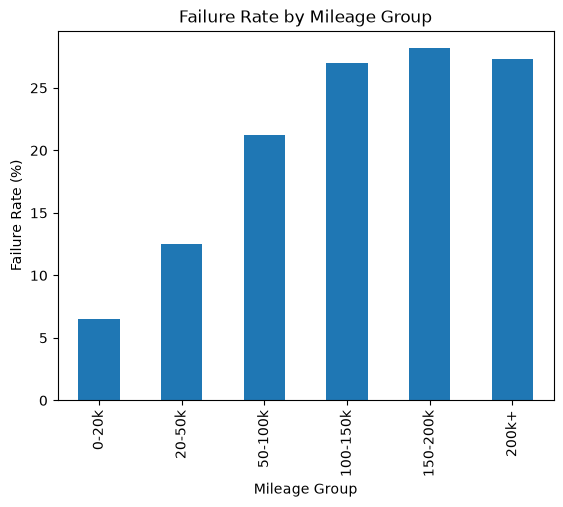

In [33]:
# Plot the failure rate for each mileage group
failure_rate.plot(kind="bar")

# Add a title and axis labels to the chart
plt.title("Failure Rate by Mileage Group")
plt.xlabel("Mileage Group")
plt.ylabel("Failure Rate (%)")

# Display the chart
plt.show()

### Observation

The failure rate generally increases as vehicle mileage increases.
The highest failure rate is observed in the 150–200k mileage group,
while the 200k+ group shows a slight decrease.

------------

## Combined Analysis

This analysis examines the relationship between vehicle age and mileage to understand how these factors together are associated with vehicle failure rates.

In [34]:
# Calculate vehicle age in years using the test date and first use date
df["vehicle_age"] = (
    df["test_date"].dt.year - df["first_use_date"].dt.year
)

In [35]:
# Define age ranges for grouping vehicles by their age
age_bins = [0, 3, 5, 8, 10, 15, np.inf]

# Define labels for each vehicle age range
age_labels = ["0-3", "3-5", "5-8", "8-10", "10-15", "15+"]

# Group vehicles based on their calculated age
df["age_group"] = pd.cut(
    df["vehicle_age"],
    bins=age_bins,
    labels=age_labels
)

In [36]:
# Calculate the failure rate for each vehicle age group
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
age_failure_rate = (
    df.groupby("age_group", observed=True)["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
)

age_failure_rate

age_group
0-3       9.025593
3-5       9.963229
5-8      14.184680
8-10     19.226789
10-15    24.323341
15+      27.840759
Name: test_result, dtype: float64

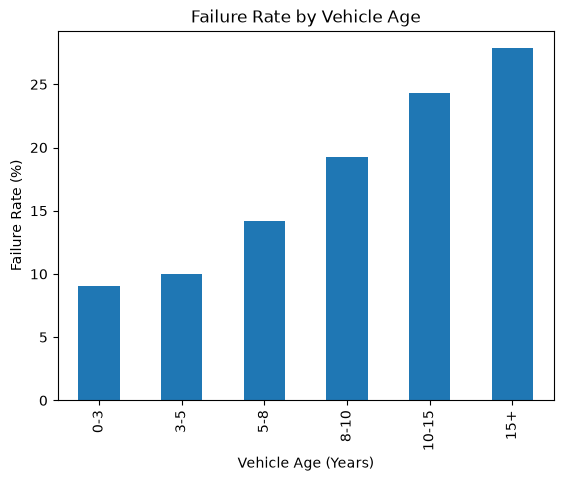

In [37]:
# Plot the failure rate for each vehicle age group
age_failure_rate.plot(kind="bar")

# Add a title and axis labels to the chart
plt.title("Failure Rate by Vehicle Age")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Failure Rate (%)")

# Display the chart
plt.show()

### Observation

The failure rate generally increases with vehicle age.
The 15+ year group has the highest failure rate, while the 0–3 year group has the lowest.

--------------------------

## Make-wise Failure Analysis

To identify whether failure patterns vary across different vehicle manufacturers,
the failure rate is compared by vehicle make.

In [38]:
# Count the number of tests for each vehicle make
make_counts = df["make"].value_counts()

# Keep only vehicle makes with at least 100 tests
# This reduces the effect of very small sample sizes
valid_makes = make_counts[make_counts >= 100].index

# Calculate the failure rate for each valid vehicle make
make_failure_rate = (
    df[df["make"].isin(valid_makes)]
    .groupby("make")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the 10 vehicle makes with the highest failure rates
make_failure_rate.head(10)

make
TALBOT           35.239852
DAEWOO           32.881356
PROTON           30.851064
GREAT WALL       29.629630
CHRYSLER-JEEP    29.427981
CHEVROLET        29.296132
LDV              29.156816
BEDFORD          28.971963
ROVER            28.519553
RELIANT          28.368794
Name: test_result, dtype: float64

In [39]:
# Define mileage ranges
bins = [0, 20000, 50000, 100000, 150000, 200000, np.inf]

# Define labels for each mileage range
labels = ["0-20k", "20-50k", "50-100k", "100-150k", "150-200k", "200k+"]

# Group vehicles based on their mileage
df["mileage_group"] = pd.cut(
    df["test_mileage"],
    bins=bins,
    labels=labels
)

In [40]:
# Define mileage ranges
bins = [0, 20000, 50000, 100000, 150000, 200000, np.inf]

# Define labels for each mileage range
labels = ["0-20k", "20-50k", "50-100k", "100-150k", "150-200k", "200k+"]

# Group vehicles based on their mileage
df["mileage_group"] = pd.cut(
    df["test_mileage"],
    bins=bins,
    labels=labels
)

<Axes: ylabel='make'>

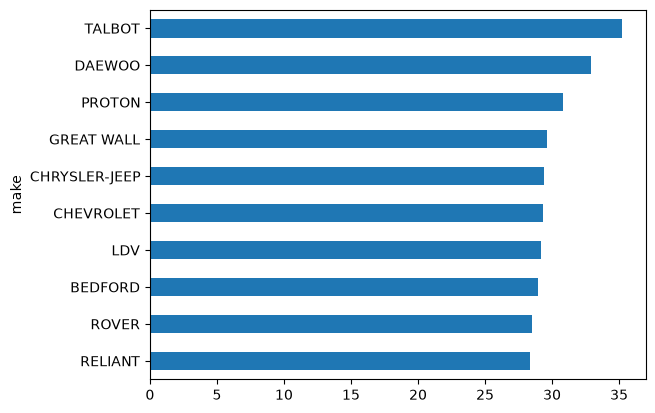

In [41]:
# Plot the 10 vehicle makes with the highest failure rates
make_failure_rate.head(10).sort_values().plot(kind="barh")

### Observation

The failure rate varies across vehicle makes.
TALBOT has the highest failure rate among the selected makes,
while RELIANT has the lowest.

------------------------

## Fuel Type-wise Failure Analysis

To understand whether vehicle failure patterns vary across different fuel types,
the failure rate is compared by fuel type.

In [42]:
# Calculate the failure rate for each fuel type
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
fuel_failure_rate = (
    df.groupby("fuel_type")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each fuel type
fuel_failure_rate

fuel_type
CN                         25.000000
LP                         24.423480
DI                         21.452381
GA                         20.000000
PE                         19.411535
GD                         18.750000
GB                         14.611872
OT                         14.395393
Electric                   14.255469
Hybrid Electric (Clean)    12.028250
FC                         12.000000
EL                         10.806941
ED                         10.588488
HY                          9.454457
ST                          0.000000
Name: test_result, dtype: float64

In [43]:
# Count the number of tests recorded for each fuel type
fuel_counts = df["fuel_type"].value_counts()

# Display the test count for each fuel type
fuel_counts

fuel_type
PE                         1973610
DI                         1733719
HY                           78344
Hybrid Electric (Clean)      27186
EL                           23050
Electric                      5668
ED                            4656
OT                            1042
LP                             954
GB                             219
FC                              25
GA                              20
GD                              16
CN                               8
ST                               1
Name: count, dtype: int64

----------------------------

### Fuel Type-wise Failure Analysis

This analysis examines whether vehicle failure rates vary across different fuel types.
Understanding fuel-type patterns can help identify whether certain powertrain categories
show different failure behaviour.

In [44]:
# Calculate the failure rate for each fuel type
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
fuel_failure_rate = (
    df.groupby("fuel_type")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each fuel type
fuel_failure_rate

fuel_type
CN                         25.000000
LP                         24.423480
DI                         21.452381
GA                         20.000000
PE                         19.411535
GD                         18.750000
GB                         14.611872
OT                         14.395393
Electric                   14.255469
Hybrid Electric (Clean)    12.028250
FC                         12.000000
EL                         10.806941
ED                         10.588488
HY                          9.454457
ST                          0.000000
Name: test_result, dtype: float64

In [45]:
# Define readable names for the fuel type codes
fuel_mapping = {
    "PE": "Petrol",
    "DI": "Diesel",
    "HY": "Hydrogen",
    "EL": "Electric",
    "ED": "Electric Diesel",
    "LP": "LPG",
    "OT": "Other",
    "Electric": "Electric",
    "Hybrid Electric (Clean)": "Hybrid Electric"
}

In [46]:
# Convert fuel type codes into readable fuel type names
df["fuel_type_name"] = df["fuel_type"].map(fuel_mapping)

# Calculate the failure rate for each named fuel type
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
fuel_failure_rate_named = (
    df.groupby("fuel_type_name")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each fuel type
fuel_failure_rate_named

fuel_type_name
LPG                24.423480
Diesel             21.452381
Petrol             19.411535
Other              14.395393
Hybrid Electric    12.028250
Electric           11.487569
Electric Diesel    10.588488
Hydrogen            9.454457
Name: test_result, dtype: float64

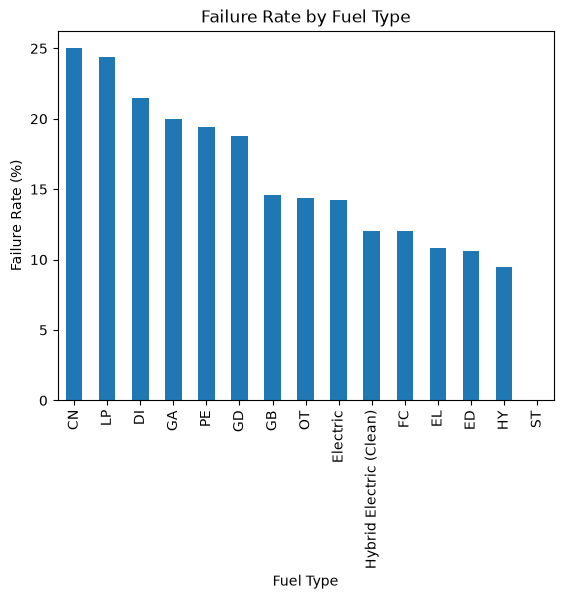

In [47]:
# Plot the failure rate for each fuel type
fuel_failure_rate.plot(kind="bar")

# Add a title and axis labels to the chart
plt.title("Failure Rate by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Failure Rate (%)")

# Display the chart
plt.show()

In [48]:
# Count the number of tests for each fuel type
fuel_counts = df["fuel_type"].value_counts()

# Keep only fuel types with at least 100 tests
# This avoids unreliable failure rates from very small sample sizes
valid_fuels = fuel_counts[fuel_counts >= 100].index

# Calculate the failure rate for each valid fuel type
fuel_failure_rate = (
    df[df["fuel_type"].isin(valid_fuels)]
    .groupby("fuel_type")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each fuel type
fuel_failure_rate

fuel_type
LP                         24.423480
DI                         21.452381
PE                         19.411535
GB                         14.611872
OT                         14.395393
Electric                   14.255469
Hybrid Electric (Clean)    12.028250
EL                         10.806941
ED                         10.588488
HY                          9.454457
Name: test_result, dtype: float64

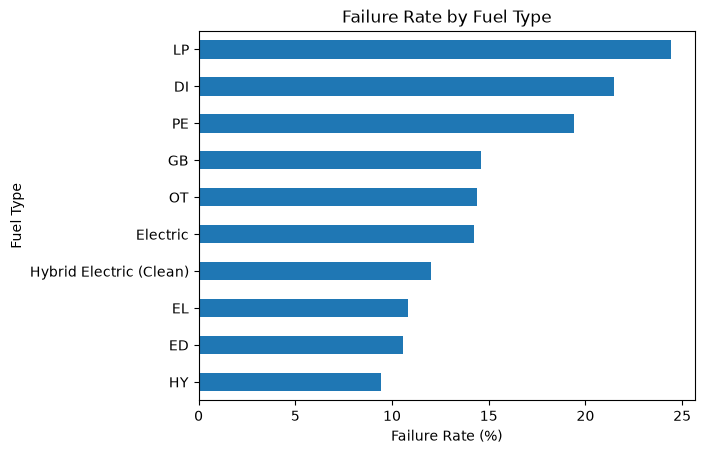

In [49]:
# Plot the fuel types in ascending order of failure rate
fuel_failure_rate.sort_values().plot(kind="barh")

# Add a title and axis labels to the chart
plt.title("Failure Rate by Fuel Type")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Fuel Type")

# Display the chart
plt.show()

### Observation

The failure rate varies across different fuel types.
Among the fuel types with at least 100 tests, LPG shows the highest failure rate,
while Hydrogen shows the lowest failure rate.

This indicates that failure patterns differ across fuel types in the January 2024 dataset.

-------------------------------------------------------------

### Vehicle Class-wise Failure Analysis

This analysis examines whether failure rates vary across different vehicle classes.
It helps identify whether certain vehicle categories show different failure patterns.

In [50]:
# Remove leading and trailing spaces from vehicle class values
# This ensures consistent vehicle class categories for analysis
df["test_class_id"] = df["test_class_id"].astype(str).str.strip()

In [51]:
# Count the number of MOT tests recorded for each vehicle class
df["test_class_id"].value_counts()

test_class_id
4    3670487
7     126845
2      31878
1      14424
5       4385
3        499
Name: count, dtype: int64

### Vehicle Class-wise Failure Analysis

This analysis examines whether failure rates vary across different vehicle classes.
It helps identify whether certain vehicle classes show different failure patterns.

In [52]:
# Calculate the failure rate for each vehicle class
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
class_failure_rate = (
    df.groupby("test_class_id")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each vehicle class
class_failure_rate

test_class_id
7    24.091608
4    19.998028
5    19.498290
1    14.954243
3    14.028056
2     7.095803
Name: test_result, dtype: float64

### Test Type-wise Failure Analysis

This analysis examines whether failure rates vary across different MOT test types.
It helps identify different failure patterns based on the type of test conducted.

In [53]:
# Calculate the failure rate for each test type
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
test_type_failure_rate = (
    df.groupby("test_type")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each test type
test_type_failure_rate

test_type
EI    81.818182
NT    24.092563
ES    16.666667
RT     0.407490
Name: test_result, dtype: float64

In [54]:
# Count the number of MOT tests recorded for each test type
df["test_type"].value_counts()

test_type
NT    3184435
RT     664066
EI         11
ES          6
Name: count, dtype: int64

In [55]:
# Select the main MOT test types for meaningful comparison
valid_test_types = ["NT", "RT"]

# Calculate the failure rate for each selected test type
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
test_type_failure_rate = (
    df[df["test_type"].isin(valid_test_types)]
    .groupby("test_type")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for the selected test types
test_type_failure_rate

test_type
NT    24.092563
RT     0.407490
Name: test_result, dtype: float64

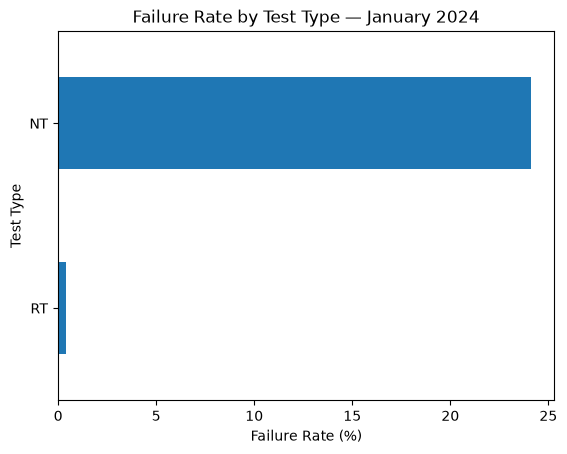

In [56]:
# Plot the failure rate for the selected test types
test_type_failure_rate.sort_values().plot(kind="barh")

# Add a title and axis labels to the chart
plt.title("Failure Rate by Test Type — January 2024")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Test Type")

# Display the chart
plt.show()

### Observation

In the January 2024 dataset, the failure rate for Normal Tests (NT) is 24.09%, while the failure rate for Retests (RT) is 0.41%.

----------------

### Engine Capacity-wise Failure Analysis

This analysis examines whether failure rates vary across different engine capacity ranges.
It helps identify whether vehicle engine size is associated with different failure patterns.

In [57]:
# Define engine capacity ranges for grouping vehicles
cc_bins = [0, 1000, 1500, 2000, 3000, np.inf]

# Define labels for each engine capacity range
cc_labels = ["0-1000", "1001-1500", "1501-2000", "2001-3000", "3001+"]

# Group vehicles based on their engine capacity
df["cc_group"] = pd.cut(
    df["cylinder_capacity"],
    bins=cc_bins,
    labels=cc_labels
)

In [58]:
# Calculate the failure rate for each engine capacity group
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
cc_failure_rate = (
    df.groupby("cc_group", observed=True)["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
)

# Display the failure rate for each engine capacity group
cc_failure_rate

cc_group
0-1000       15.597045
1001-1500    20.215030
1501-2000    20.890864
2001-3000    20.919307
3001+        16.016663
Name: test_result, dtype: float64

### Observation

Failure rates vary across different engine capacity groups.
The 2001–3000 cc group shows the highest failure rate at 20.92%,
while the 0–1000 cc group shows the lowest at 15.60%.

In [59]:
# Count the number of MOT tests recorded for each vehicle colour
# Display the 15 most common colours
df["colour"].value_counts().head(15)

colour
WHITE        765859
BLACK        737339
SILVER       594533
BLUE         589551
GREY         573882
RED          379823
GREEN         67607
ORANGE        28144
BROWN         22060
YELLOW        21474
BEIGE         20785
PURPLE        12891
BRONZE        10329
GOLD           9407
TURQUOISE      3761
Name: count, dtype: int64

In [60]:
# Count the number of MOT tests for each vehicle colour
colour_counts = df["colour"].value_counts()

# Keep only colours with at least 100 tests
# This avoids unreliable failure rates from very small sample sizes
valid_colours = colour_counts[colour_counts >= 100].index

# Calculate the failure rate for each valid vehicle colour
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
colour_failure_rate = (
    df[df["colour"].isin(valid_colours)]
    .groupby("colour")["test_result"]
    .apply(lambda x: (x == "F").mean() * 100)
    .sort_values(ascending=False)
)

# Display the failure rate for each vehicle colour
colour_failure_rate

colour
BEIGE           23.305268
GREEN           22.985785
MAROON          22.312312
GOLD            22.249389
SILVER          22.220634
YELLOW          21.691348
PURPLE          21.619735
WHITE           20.046510
BLACK           20.016980
CREAM           20.005936
BLUE            19.967738
PINK            19.681835
RED             19.509877
TURQUOISE       19.356554
BROWN           17.946510
GREY            17.719496
BRONZE          16.942589
ORANGE          16.536384
MULTI-COLOUR    13.490623
Name: test_result, dtype: float64

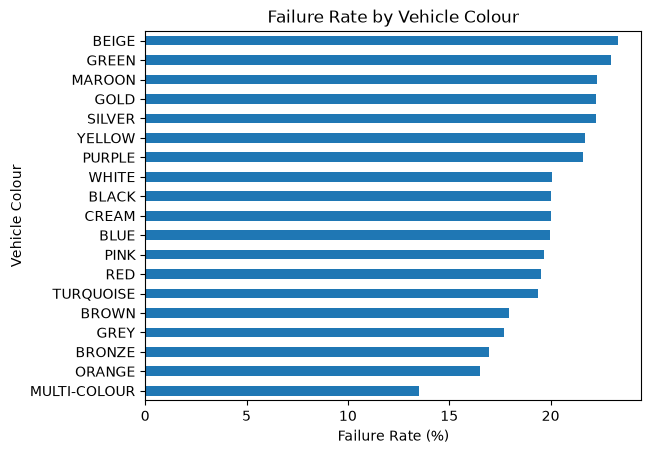

In [61]:
# Plot the failure rate for each vehicle colour
colour_failure_rate.sort_values().plot(kind="barh")

# Add a title and axis labels to the chart
plt.title("Failure Rate by Vehicle Colour")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Vehicle Colour")

# Display the chart
plt.show()

### Observation

The failure rate varies across different vehicle colours.
Among the colours analysed, Beige has the highest failure rate at 23.31%,
while Multi-Colour has the lowest at 13.49%.

----------------

### Failure Item Type Analysis

This analysis examines the distribution of different failure item types recorded in the MOT failure item data.

In [62]:
# Define the file path for the January 2024 MOT failure item data
failure_file = r"D:\EDA PROJECT\MOT Testing data failure item (2024)\test_item_202401.csv"

# Load the failure item data into a pandas DataFrame
# The escape character helps handle special characters in the CSV file
failure_df = pd.read_csv(
    failure_file,
    escapechar="\\"
)

C:\Users\User\AppData\Local\Temp\ipykernel_12380\468078443.py:6: DtypeWarning: Columns (0: test_id, 1: rfr_id, 2: mot_test_rfr_location_type_id) have mixed types. Specify dtype option on import or set low_memory=False.
  failure_df = pd.read_csv(


In [63]:
# Check the number of rows and columns in the failure item dataset
failure_df.shape

(10451564, 6)

In [64]:
# Count the number of failure items recorded for each failure type
failure_df["rfr_type_code"].value_counts()

rfr_type_code
A                6808837
F                2500268
M                 798162
P                 344282
rfr_type_code         15
Name: count, dtype: int64

In [65]:
# Display the first five rows to inspect the structure and sample records
failure_df.head()

,test_id,rfr_id,rfr_type_code,mot_test_rfr_location_type_id,dangerous_mark,completed_date
0,1479190053,31361,A,9,NaN,2024-01-01T11:59:33.000Z
1,1479190053,30335,A,7,NaN,2024-01-01T11:59:33.000Z
2,1479190053,32017,P,25,NaN,2024-01-01T11:59:33.000Z
3,1479190053,30202,A,1,NaN,2024-01-01T11:59:33.000Z
4,1479190053,30335,A,9,NaN,2024-01-01T11:59:33.000Z


In [66]:
# Count the occurrences of each specific failure item
# Display the 10 most frequently recorded failure items
failure_df["rfr_id"].value_counts().head(10)

rfr_id
31194    1080680
30335     497425
32037     462700
30329     424086
31322     366543
30305     313866
31194     250376
31940     213210
31226     192243
32115     159563
Name: count, dtype: int64

In [67]:
# Load the official MOT item detail lookup file
# Pipe "|" is used as the delimiter and all columns are read as strings
lookup_df = pd.read_csv(
    r"C:\Users\User\Downloads\lookup\item_detail.csv",
    sep="|",
    dtype=str
)

# Display the column names of the lookup dataset
lookup_df.columns

Index(['rfr_id', 'test_class_id', 'test_item_id', 'minor_item',
       'rfr_deficiency_category', 'rfr_desc', 'rfr_loc_marker',
       'rfr_insp_manual_desc', 'rfr_advisory_text',
       'test_item_set_section_id'],
      dtype='str')

In [68]:
# Merge the failure item descriptions from the lookup dataset
# Drop duplicate lookup entries to avoid duplicate rows after merging
failure_df = failure_df.merge(
    lookup_df[["rfr_id", "rfr_desc"]].drop_duplicates(),
    on="rfr_id",
    how="left"
)

In [69]:
# Count the frequency of each specific defect description
# Display the 10 most frequently recorded vehicle defects
failure_df["rfr_desc"].value_counts().head(10)

rfr_desc
tread depth below requirements of 1.6mm                                        250376
in such a condition that it is seriously weakened                              116112
pin or bush excessively worn                                                   108184
less than 1.5 mm thick                                                         100436
has a tear, caused by separation or partial failure of its structure            99794
excessively corroded                                                            70382
not working                                                                     59817
ball joint excessively worn                                                     55566
leaking excessively from engine                                                 47554
corroded so that its cross sectional area is reduced and seriously weakened     43852
Name: count, dtype: int64

In [70]:
# Count the number of failure items recorded for each failure type
failure_df["rfr_type_code"].value_counts()

rfr_type_code
A                6808837
F                2500268
M                 798162
P                 344282
rfr_type_code         15
Name: count, dtype: int64

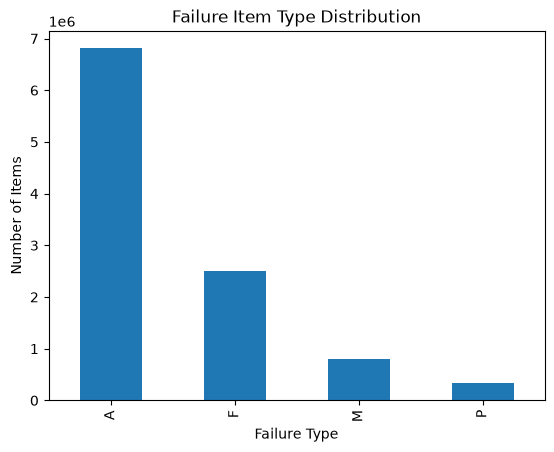

In [71]:
# Plot the distribution of failure items by failure type
# Exclude the header-like value "rfr_type_code" if present
failure_df["rfr_type_code"].value_counts().drop(
    "rfr_type_code",
    errors="ignore"
).plot(kind="bar")

# Add a title and axis labels to the chart
plt.title("Failure Item Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Number of Items")

# Display the chart
plt.show()

### Observation

The failure item records are distributed across four main failure types: A, F, M, and P. Type A has the highest number of records, followed by F, M, and P.

---------------

### Dangerous Failure Mark Analysis

This analysis examines the dangerous mark recorded against MOT failure items to understand how frequently dangerous defects are identified.

In [72]:
# Count dangerous marks, including missing values
# dropna=False ensures that records without a dangerous mark are also counted
failure_df["dangerous_mark"].value_counts(dropna=False)

dangerous_mark
NaN               10008288
D                   443261
dangerous_mark          15
Name: count, dtype: int64

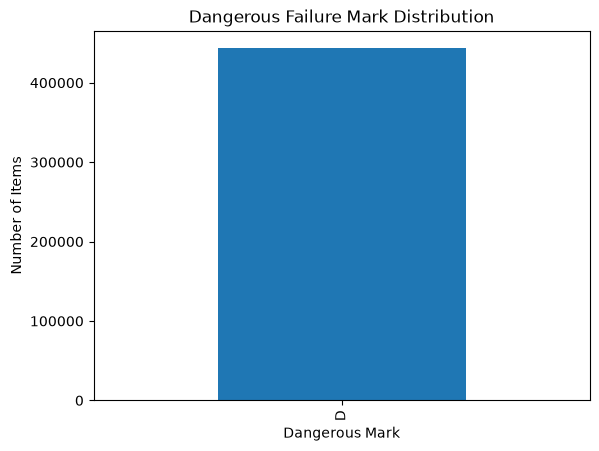

In [73]:
# Plot the distribution of dangerous failure marks
# Exclude the header-like value "dangerous_mark" if present
failure_df["dangerous_mark"].value_counts().drop(
    ["dangerous_mark"],
    errors="ignore"
).plot(kind="bar")

# Add a title and axis labels to the chart
plt.title("Dangerous Failure Mark Distribution")
plt.xlabel("Dangerous Mark")
plt.ylabel("Number of Items")

# Display the chart
plt.show()

### Observation

Most failure item records do not have a dangerous mark recorded. A smaller portion of records are marked as dangerous, with 443,261 items having a dangerous mark of D.

-------

### Vehicle Defect Location Analysis

This analysis examines the recorded defect locations in MOT failure items to identify which vehicle positions are associated with reported defects. The location information describes the lateral, longitudinal, and vertical position of the defect on the vehicle.

In [74]:
# Load the official MOT failure location lookup file
# Pipe "|" is used as the delimiter and all columns are read as strings
location_df = pd.read_csv(
    r"C:\Users\User\Downloads\lookup\mdr_rfr_location.csv",
    sep="|",
    dtype=str
)

# Display the column names of the location lookup dataset
location_df.columns

Index(['id', 'lateral', 'longitudinal', 'vertical'], dtype='str')

In [75]:
# Display the first 10 rows of the location lookup dataset
# This helps inspect the available vehicle defect location details
location_df.head(10)

,id,lateral,longitudinal,vertical
0,1,NaN,NaN,NaN
1,3,Nearside,NaN,NaN
2,5,Offside,NaN,NaN
3,7,NaN,Front,NaN
4,9,NaN,Rear,NaN
5,11,Centre,Front,Upper
6,13,Nearside,Rear,NaN
7,15,Centre,NaN,NaN
8,17,Offside,Rear,NaN
9,19,Offside,Rear,Outer


In [76]:
# Count the number of failure items recorded for each defect location
# Display the 15 most frequently recorded location identifiers
failure_df["mot_test_rfr_location_type_id"].value_counts().head(15)

mot_test_rfr_location_type_id
27    1271561
25    1258298
1     1154578
13     993739
17     983124
7      771405
9      678024
27     294644
25     292044
1      265052
3      264870
5      259249
13     228313
17     225647
7      181615
Name: count, dtype: int64

### Location Data Preparation

The location identifiers are cleaned by removing leading or trailing spaces to ensure consistent matching with the official location lookup data.

In [77]:
# Remove leading and trailing spaces from location identifiers
# This ensures consistent matching with the location lookup dataset
failure_df["mot_test_rfr_location_type_id"] = (
    failure_df["mot_test_rfr_location_type_id"]
    .astype(str)
    .str.strip()
)

In [78]:
# Merge the official defect location details into the failure dataset
# Match the cleaned location ID with the lookup table ID
failure_df = failure_df.merge(
    location_df,
    left_on="mot_test_rfr_location_type_id",
    right_on="id",
    how="left"
)

In [79]:
# Count failure items by lateral defect location, including missing values
# dropna=False ensures records without a lateral location are also counted
failure_df["lateral"].value_counts(dropna=False)

lateral
Nearside    3523313
Offside     3514973
NaN         3302670
Central      110608
Name: count, dtype: int64

### Observation

The analysis shows that Nearside and Offside defects are the most frequently recorded lateral locations, while Centre defects are less common. A substantial number of records have no lateral location recorded.

In [80]:
# Count failure items by longitudinal defect location, including missing values
# dropna=False ensures records without a longitudinal location are also counted
failure_df["longitudinal"].value_counts(dropna=False)

longitudinal
Front    4777389
Rear     3530719
NaN      2143456
Name: count, dtype: int64

### Observation

The analysis shows that Front is the most frequently recorded longitudinal defect location, followed by Rear. A smaller number of records have no longitudinal location recorded.

In [81]:
# Count failure items by vertical defect location, including missing values
# dropna=False ensures records without a vertical location are also counted
failure_df["vertical"].value_counts(dropna=False)

vertical
NaN      9500684
Lower     317631
Inner     310149
Outer     206754
Upper     116346
Name: count, dtype: int64

### Observation

The analysis shows that Lower is the most frequently recorded vertical defect location, followed by Inner, Outer, and Upper. However, most failure records do not contain a vertical location.

-------


### Top Vehicle Defect Analysis

This analysis examines the most frequently recorded vehicle defects to identify the common defect patterns found in MOT failure items.

In [82]:
# Count the frequency of each specific defect description
# Display the 10 most frequently recorded vehicle defects
failure_df["rfr_desc"].value_counts().head(10)

rfr_desc
tread depth below requirements of 1.6mm                                        250376
in such a condition that it is seriously weakened                              116112
pin or bush excessively worn                                                   108184
less than 1.5 mm thick                                                         100436
has a tear, caused by separation or partial failure of its structure            99794
excessively corroded                                                            70382
not working                                                                     59817
ball joint excessively worn                                                     55566
leaking excessively from engine                                                 47554
corroded so that its cross sectional area is reduced and seriously weakened     43852
Name: count, dtype: int64

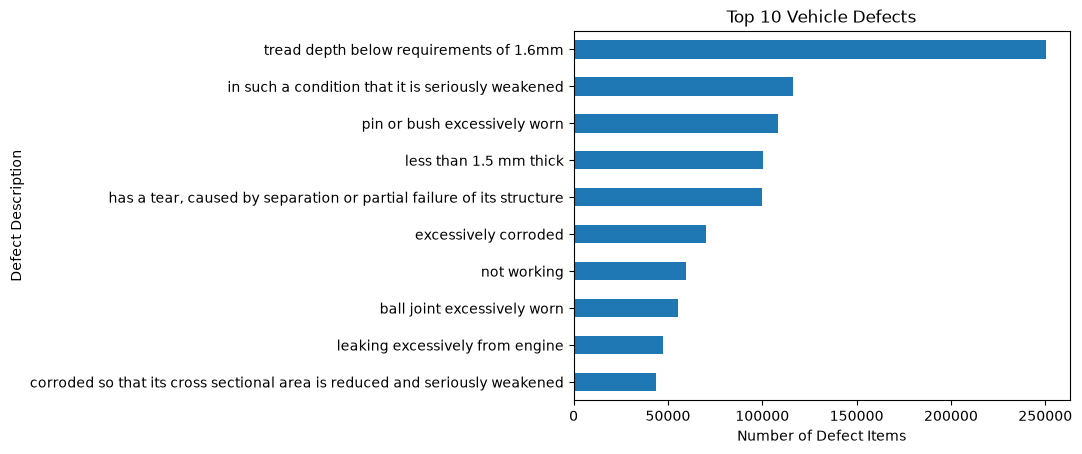

In [83]:
# Select the 10 most frequently recorded vehicle defects
top_defects = failure_df["rfr_desc"].value_counts().head(10)

# Plot the top 10 defects in ascending order for easier comparison
top_defects.sort_values().plot(kind="barh")

# Add a title and axis labels to the chart
plt.title("Top 10 Vehicle Defects")
plt.xlabel("Number of Defect Items")
plt.ylabel("Defect Description")

# Display the chart
plt.show()

### Observation

The analysis shows that tyre tread defects are the most frequently recorded vehicle defect, followed by weakened components, worn pins or bushes, and other structural or component-related defects. This indicates that tyre, wear-related, and structural defects are common patterns in the January 2024 MOT failure data.

---

### Dangerous Defect by Failure Type

This analysis examines how dangerous defects are distributed across different failure item types in the MOT failure data.

In [84]:
# Compare dangerous failure marks across different failure item types
# This creates a cross-tabulation showing the count of each dangerous mark
# for each failure type
dangerous_by_type = pd.crosstab(
    failure_df["rfr_type_code"],
    failure_df["dangerous_mark"]
)

# Display the cross-tabulated results
dangerous_by_type

dangerous_mark,D,dangerous_mark
rfr_type_code,,
A,1184,0
F,425335,0
P,16742,0
rfr_type_code,0,15


### Observation

The analysis shows that dangerous defects are predominantly associated with failure type F, with 425,335 dangerous items. Failure type P has 16,742 dangerous items, while type A has 1,184. No dangerous items are recorded for type M in this dataset.

---

### Defect Category Analysis

This analysis examines the distribution of MOT failure items across different defect categories to identify the major categories contributing to vehicle defects.

In [85]:
# Select the failure item ID and its corresponding defect description
# This helps inspect the mapping between defect codes and descriptions
lookup_df[["rfr_id", "rfr_desc"]]

,rfr_id,rfr_desc
0,4,missing
1,4,missing
2,5,damaged and function impaired
3,5,damaged and function impaired
4,6,deteriorated and function impaired
...,...,...
21064,40683,has negligible damping effect
21065,40684,unable to be tested
21066,40684,unable to be tested
21067,40685,unable to be tested


In [86]:
# Merge the defect category information from the lookup dataset
# Drop duplicate lookup entries to avoid creating duplicate rows
failure_df = failure_df.merge(
    lookup_df[["rfr_id", "rfr_deficiency_category"]].drop_duplicates(),
    on="rfr_id",
    how="left"
)

In [87]:
# Count the number of failure items in each defect category
# This helps identify the most common defect categories
failure_category = (
    failure_df["rfr_deficiency_category"]
    .value_counts()
)

# Display the defect category counts
failure_category

rfr_deficiency_category
Major               1107408
Dangerous            638985
Minor                152096
Pre-EU Directive      67576
Name: count, dtype: int64

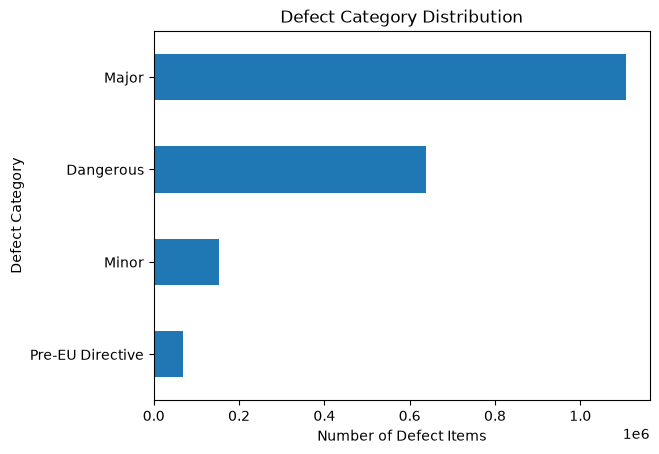

In [88]:
# Plot the distribution of defect categories
failure_category.sort_values().plot(kind="barh")

# Add a title and axis labels to the chart
plt.title("Defect Category Distribution")
plt.xlabel("Number of Defect Items")
plt.ylabel("Defect Category")

# Display the chart
plt.show()

### Observation

The analysis shows that Major defects are the most frequently recorded category, followed by Dangerous and Minor defects. Pre-EU Directive defects are the least frequent category in the January 2024 MOT failure data. This indicates that Major and Dangerous defects form a significant portion of the recorded vehicle defect items.

---------

### Age and Mileage Combined Failure Analysis

This analysis examines vehicle failure rates based on the combination of vehicle age and mileage to identify whether older and higher-mileage vehicles show different failure patterns.

In [89]:
# Calculate the failure rate for each combination of vehicle age and mileage group
# A test is considered a failure when the test result is "F"
# Multiply by 100 to express the failure rate as a percentage
age_mileage_failure = pd.crosstab(
    df["age_group"],
    df["mileage_group"],
    values=df["test_result"],
    aggfunc=lambda x: (x == "F").mean() * 100
)

# Display the combined age and mileage failure rates
age_mileage_failure

mileage_group,0-20k,20-50k,50-100k,100-150k,150-200k,200k+
age_group,,,,,,
0-3,4.870769,9.956187,15.771387,17.996698,17.878788,16.831683
3-5,5.537112,9.908451,14.301922,16.360800,17.800559,15.343915
5-8,7.000139,11.802282,16.218075,19.631254,19.755570,19.354279
8-10,8.712459,14.322400,19.978911,23.090326,23.988020,22.721779
10-15,10.447382,16.702059,23.865877,27.189662,27.747076,26.998658
15+,12.226488,19.033139,26.923631,30.092061,30.467423,30.180103


### Observation

The analysis shows that failure rates generally increase as both vehicle age and mileage increase. The highest failure rate is observed for vehicles aged 15+ years with 150-200k mileage at 30.47%, while newer vehicles with lower mileage show much lower failure rates. This indicates that the combination of vehicle age and mileage is associated with higher vehicle failure rates.

----

## Final Project Conclusion

The analysis of January 2024 MOT data reveals several important vehicle failure patterns. Failure rates generally increase with vehicle age and mileage, with older and higher-mileage vehicles showing higher failure rates. Failure rates also vary across vehicle makes, fuel types, vehicle classes, engine capacity groups, and test types.

The combined age and mileage analysis shows that vehicles with both higher age and higher mileage tend to have higher failure rates. The failure item analysis further identifies common defects such as tyre tread problems, worn components, structural defects, and other vehicle-related issues.

These findings can support maintenance planning by helping fleet operators identify vehicle groups that may require closer inspection and preventive maintenance.

## Limitations

- The analysis is based on January 2024 MOT data and may not represent all months or years.
- The dataset represents MOT testing data and does not directly represent a specific delivery fleet.
- Some records contain missing values, especially mileage and engine capacity.
- The analysis identifies associations and patterns but does not establish causal relationships.
- Vehicle operating conditions, maintenance history, and driving behaviour are not fully available in the dataset.

## Future Scope

- Extend the analysis to all 2024 MOT months and multiple years.
- Build a machine learning model to predict vehicle failure risk.
- Use previous MOT history and defect history as predictive features.
- Develop a vehicle risk score for maintenance prioritisation.
- Build a dashboard to help fleet operators monitor vehicle reliability and maintenance needs.